# Laboratorul 1 — Explorarea și procesarea datelor NYC în PySpark

Notebookul parcurge cerințele laboratorului cu explicații scurte și cod: alegerea datelor, ingestie, stocare, curățare, analiză, vizualizare și simulare Kafka → Spark Structured Streaming → MongoDB.

**Dimensiunea setului local:** fișierele Parquet însumează aproximativ 395 MB, sub pragul de 2 GB din cerință. Lucrăm cu datele disponibile local; această limitare rămâne neschimbată și nu pretindem că pragul este îndeplinit.

## Planul notebookului

1. Descriu sursele NYC și verific dimensiunea și structura fișierelor locale.
2. Citesc Parquet cu PySpark și salvez tabelele curate în data lake local.
3. Verific valorile lipsă/invalide, convertesc tipurile și curăț ambele surse.
4. Calculez metrici Spark SQL cu mediile separate după tipul de plată și fac un join explicat.
5. Generez grafice și insight-uri calculate din rezultate.
6. Simulez un flux Kafka configurabil, agreg în ferestre cu Spark Streaming și scriu în MongoDB.
7. Construiesc un dashboard interactiv în notebook și exporturi CSV pentru Tableau/Power BI.

**Înainte de rulare:** instalează dependența pentru dashboard cu `%pip install -r requirements-lab1.txt`. Pentru streaming, pornește Kafka și MongoDB din `docker-compose.streaming.yml`. La prima pornire, Spark descarcă un conector Maven pentru Kafka, deci containerul are nevoie de internet. Repornește kernelul înainte de Run All dacă Spark fusese pornit anterior fără conector.

## 1. Alegerea dataset-ului

Folosesc NYC Citywide Payroll Data și NYC Civil List, publicate de NYC Open Data. Payroll conține înregistrări salariale pe agenție, an fiscal, funcție și tip de plată; Civil List oferă o a doua sursă pentru comparații de salarii și personal.

- Payroll: https://data.cityofnewyork.us/City-Government/Citywide-Payroll-Data-Fiscal-Year-/k397-673e/about_data
- Civil List: https://data.cityofnewyork.us/City-Government/Civil-List/5scm-b38n

Le-am ales fiindcă sunt date publice, au milioane de înregistrări și permit agregări pe agenție și an. Fișierele locale sunt copii Parquet deja descărcate; verificarea dimensiunii de mai jos arată transparent dacă respectă cerința de minimum 2 GB.

## 2. Pregătirea mediului și ingestia PySpark

Notebookul citește fișierele Parquet deja descărcate în `nyc-data/`; nu reia descărcarea API la fiecare rulare. Scriptul existent `nyc-data/upload_nyc_data.py` descarcă Civil List din NYC Open Data și o salvează în Parquet; Payroll este furnizat local ca fișier Parquet. Separarea ingestiei inițiale de procesarea Spark face rulările repetabile și evită descărcarea a milioane de rânduri la fiecare Run All.

Conectorul Spark-Kafka este configurat înainte de crearea SparkSession-ului, fiindcă pachetul trebuie încărcat la pornirea Spark.

In [12]:
from pathlib import Path
import os

from pyspark import __version__ as SPARK_VERSION
from pyspark.sql import SparkSession, functions as F

candidates = [
    Path.cwd(),
    Path.cwd() / "Lab1",
    Path("/home/jovyan/work/Lab1"),
]
PROJECT_ROOT = next(
    (candidate.resolve() for candidate in candidates
     if (candidate / "nyc-data" / "nyc_payroll_data.parquet").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Nu găsesc nyc-data/nyc_payroll_data.parquet. "
        "Deschide notebookul din proiectul Lab1."
    )

DATA_DIR = PROJECT_ROOT / "nyc-data"
LAKE_DIR = PROJECT_ROOT / "data_lake"
LAKE_DIR.mkdir(parents=True, exist_ok=True)

spark_major = int(SPARK_VERSION.split(".", maxsplit=1)[0])
scala_binary = "2.13" if spark_major >= 4 else "2.12"
kafka_connector = (
    f"org.apache.spark:spark-sql-kafka-0-10_{scala_binary}:{SPARK_VERSION}"
)

active_spark = SparkSession.getActiveSession()
if active_spark is not None:
    loaded_packages = active_spark.sparkContext.getConf().get(
        "spark.jars.packages", ""
    )
    if kafka_connector not in loaded_packages:
        raise RuntimeError(
            "Spark a fost pornit fără conectorul Kafka. "
            "Repornește kernelul și rulează notebookul de la început."
        )

spark = (
    SparkSession.builder
    .appName("Lab1-NYC-PySpark")
    .master("local[*]")
    .config("spark.sql.adaptive.enabled", "true")
    .config("spark.jars.packages", kafka_connector)
    .getOrCreate()
)

payroll_path = DATA_DIR / "nyc_payroll_data.parquet"
civil_path = DATA_DIR / "nyc_civil_list.parquet"
for dataset_path in (payroll_path, civil_path):
    if not dataset_path.is_file():
        raise FileNotFoundError(f"Lipsește fișierul: {dataset_path}")

total_bytes = payroll_path.stat().st_size + civil_path.stat().st_size
print(f"PySpark: {SPARK_VERSION}")
print(f"Conector Kafka: {kafka_connector}")
print(f"Dimensiune Parquet combinată: {total_bytes / (1024 ** 2):.1f} MB")
print(f"Director proiect: {PROJECT_ROOT}")

payroll_df = spark.read.parquet(str(payroll_path))
civil_df = spark.read.parquet(str(civil_path))
print(f"Payroll: {payroll_df.count():,} rânduri")
print(f"Civil List: {civil_df.count():,} rânduri")
payroll_df.printSchema()
civil_df.printSchema()

PySpark: 4.2.0
Conector Kafka: org.apache.spark:spark-sql-kafka-0-10_2.13:4.2.0
Dimensiune Parquet combinată: 394.9 MB
Director proiect: /home/jovyan/work/Lab1
Payroll: 6,775,830 rânduri
Civil List: 3,237,466 rânduri
root
 |-- __id: string (nullable = true)
 |-- fiscal_year: string (nullable = true)
 |-- payroll_number: string (nullable = true)
 |-- agency_name: string (nullable = true)
 |-- last_name: string (nullable = true)
 |-- first_name: string (nullable = true)
 |-- mid_init: string (nullable = true)
 |-- agency_start_date: string (nullable = true)
 |-- work_location_borough: string (nullable = true)
 |-- title_description: string (nullable = true)
 |-- leave_status_as_of_june_30: string (nullable = true)
 |-- base_salary: string (nullable = true)
 |-- pay_basis: string (nullable = true)
 |-- regular_hours: string (nullable = true)
 |-- regular_gross_paid: string (nullable = true)
 |-- ot_hours: string (nullable = true)
 |-- total_ot_paid: string (nullable = true)
 |-- total_oth

### Stocarea în data lake local și Delta Lake

Parquet este columnar și comprimat, potrivit pentru citire eficientă în Spark. Mai jos salvăm tabelele curate în directoare separate. Delta Lake adaugă peste Parquet tranzacții ACID, istoric/versionare și operații de upsert; pentru a-l activa este necesar pachetul Delta compatibil cu versiunea Spark și configurarea lui înainte de pornirea sesiunii. În acest laborator folosim Parquet, suportat direct de mediul curent.

## 3. Curățare și transformare

Mai întâi măsurăm null-urile din sursă. Unele coloane numerice sunt șiruri, iar salarii precum “$101,270.00” nu pot fi convertite direct; eliminăm simbolul dolar și separatorul de mii, apoi folosim try_cast, care transformă valorile malformate în null în loc să oprească execuția. Excludem înregistrările fără agenție/an/salariu valid și salariile de bază zero sau negative. Valorile negative din plățile suplimentare nu sunt eliminate automat, fiindcă pot reprezenta ajustări.

In [13]:
def null_counts(dataframe, columns):
    expressions = [
        F.count(F.when(F.col(column).isNull(), 1)).alias(column)
        for column in columns
    ]
    return dataframe.agg(*expressions).first().asDict()


payroll_columns = [
    "agency_name", "fiscal_year", "base_salary", "regular_gross_paid",
    "ot_hours", "total_ot_paid", "total_other_pay",
]
civil_columns = ["agency_name", "calendar_year", "sal_rate"]

print("Null-uri în sursa Payroll:", null_counts(payroll_df, payroll_columns))
print("Null-uri în sursa Civil List:", null_counts(civil_df, civil_columns))


def numeric_column(column_name):
    return F.expr(
        "try_cast(regexp_replace(trim("
        + column_name
        + "), '[,$]', '') AS DOUBLE)"
    )


typed_payroll = payroll_df.select(
    F.trim(F.col("agency_name")).alias("agency_name"),
    F.expr("try_cast(fiscal_year AS INT)").alias("fiscal_year"),
    F.col("pay_basis"),
    F.col("work_location_borough"),
    F.col("title_description"),
    numeric_column("base_salary").alias("base_salary"),
    numeric_column("regular_gross_paid").alias("regular_gross_paid"),
    numeric_column("ot_hours").alias("ot_hours"),
    numeric_column("total_ot_paid").alias("total_ot_paid"),
    numeric_column("total_other_pay").alias("total_other_pay"),
)

typed_civil = civil_df.select(
    F.trim(F.col("agency_name")).alias("agency_name"),
    F.expr("try_cast(calendar_year AS INT)").alias("calendar_year"),
    numeric_column("sal_rate").alias("sal_rate"),
)

invalid_numeric_counts = typed_payroll.agg(
    *[
        F.count(F.when(F.col(column).isNull(), 1)).alias(column)
        for column in [
            "fiscal_year", "base_salary", "regular_gross_paid",
            "ot_hours", "total_ot_paid", "total_other_pay",
        ]
    ]
).first().asDict()
print("Null-uri după conversia numerică Payroll:", invalid_numeric_counts)

clean_payroll = typed_payroll.filter(
    F.col("agency_name").isNotNull()
    & (F.length(F.col("agency_name")) > 0)
    & F.col("fiscal_year").isNotNull()
    & F.col("base_salary").isNotNull()
    & (F.col("base_salary") > 0)
)

clean_civil = typed_civil.filter(
    F.col("agency_name").isNotNull()
    & (F.length(F.col("agency_name")) > 0)
    & F.col("calendar_year").isNotNull()
    & F.col("sal_rate").isNotNull()
    & (F.col("sal_rate") > 0)
)

print(f"Payroll păstrate: {clean_payroll.count():,}")
print(f"Civil List păstrate: {clean_civil.count():,}")
print(
    "Null-uri rămase în coloanele numerice Payroll:",
    null_counts(
        clean_payroll,
        ["base_salary", "regular_gross_paid", "ot_hours",
         "total_ot_paid", "total_other_pay"],
    ),
)

Null-uri în sursa Payroll: {'agency_name': 0, 'fiscal_year': 0, 'base_salary': 0, 'regular_gross_paid': 0, 'ot_hours': 0, 'total_ot_paid': 0, 'total_other_pay': 0}
Null-uri în sursa Civil List: {'agency_name': 0, 'calendar_year': 0, 'sal_rate': 0}
Null-uri după conversia numerică Payroll: {'fiscal_year': 0, 'base_salary': 0, 'regular_gross_paid': 0, 'ot_hours': 0, 'total_ot_paid': 0, 'total_other_pay': 0}
Payroll păstrate: 6,775,830
Civil List păstrate: 3,237,466
Null-uri rămase în coloanele numerice Payroll: {'base_salary': 0, 'regular_gross_paid': 0, 'ot_hours': 0, 'total_ot_paid': 0, 'total_other_pay': 0}


### Salvarea rezultatului curățat

Salvăm curățarea ca Parquet, separat de fișierele sursă. Astfel, etapele ulterioare pot reutiliza rezultatul fără să repete conversiile.

In [14]:
payroll_output = LAKE_DIR / "clean" / "payroll"
civil_output = LAKE_DIR / "clean" / "civil_list"

clean_payroll.write.mode("overwrite").parquet(str(payroll_output))
clean_civil.write.mode("overwrite").parquet(str(civil_output))

print(f"Payroll curățat salvat în: {payroll_output}")
print(f"Civil List curățat salvat în: {civil_output}")

Payroll curățat salvat în: /home/jovyan/work/Lab1/data_lake/clean/payroll
Civil List curățat salvat în: /home/jovyan/work/Lab1/data_lake/clean/civil_list


### De ce verificăm valorile înainte de metrici?

Un null sau un text convertit greșit poate modifica media și suma, iar salariile invalide pot distorsiona comparațiile. Numărăm explicit valorile invalide, documentăm regula de filtrare și păstrăm separat câmpurile cu ajustări posibile. Conversia și verificarea tipurilor fac calculele comparabile și reproducibile.

## 4. Analiză descriptivă cu Spark SQL

Calculăm frecvența înregistrărilor, media salariului de bază și totalurile plătite. Separăm media după pay_basis, deoarece salariile anuale și ratele orare nu trebuie interpretate ca aceeași categorie. Numărul de rânduri este număr de înregistrări, nu număr garantat de angajați unici.

In [15]:
spark.catalog.dropTempView("payroll_clean")
spark.catalog.dropTempView("civil_clean")
clean_payroll.createOrReplaceTempView("payroll_clean")
clean_civil.createOrReplaceTempView("civil_clean")

pay_basis_metrics = spark.sql("""
    SELECT
        pay_basis,
        COUNT(*) AS payroll_records,
        ROUND(AVG(base_salary), 2) AS avg_base_salary,
        ROUND(SUM(regular_gross_paid), 2) AS regular_gross_total,
        ROUND(SUM(total_ot_paid), 2) AS overtime_pay_total
    FROM payroll_clean
    GROUP BY pay_basis
    ORDER BY payroll_records DESC
""")

year_basis_metrics = spark.sql("""
    SELECT
        fiscal_year,
        pay_basis,
        COUNT(*) AS payroll_records,
        ROUND(AVG(base_salary), 2) AS avg_base_salary,
        ROUND(SUM(regular_gross_paid), 2) AS regular_gross_total,
        ROUND(SUM(total_ot_paid), 2) AS overtime_pay_total
    FROM payroll_clean
    GROUP BY fiscal_year, pay_basis
    ORDER BY fiscal_year, pay_basis
""")

annual_year_metrics = year_basis_metrics.filter(
    F.lower(F.trim("pay_basis")) == "per annum"
)

year_metrics = spark.sql("""
    SELECT
        fiscal_year,
        COUNT(*) AS payroll_records,
        ROUND(SUM(regular_gross_paid), 2) AS regular_gross_total,
        ROUND(SUM(total_ot_paid), 2) AS overtime_pay_total
    FROM payroll_clean
    GROUP BY fiscal_year
    ORDER BY fiscal_year
""")

agency_metrics = spark.sql("""
    SELECT
        agency_name,
        COUNT(*) AS payroll_records,
        ROUND(SUM(regular_gross_paid), 2) AS regular_gross_total,
        ROUND(SUM(total_ot_paid), 2) AS overtime_pay_total
    FROM payroll_clean
    GROUP BY agency_name
    ORDER BY payroll_records DESC
""")

annual_agency_metrics = spark.sql("""
    SELECT
        agency_name,
        COUNT(*) AS annual_payroll_records,
        ROUND(AVG(base_salary), 2) AS avg_annual_base_salary,
        ROUND(SUM(regular_gross_paid), 2) AS regular_gross_total,
        ROUND(SUM(total_ot_paid), 2) AS overtime_pay_total
    FROM payroll_clean
    WHERE LOWER(TRIM(pay_basis)) = 'per annum'
    GROUP BY agency_name
    ORDER BY annual_payroll_records DESC
""")

agency_year_metrics = spark.sql("""
    SELECT
        agency_name,
        fiscal_year,
        pay_basis,
        COUNT(*) AS payroll_records,
        ROUND(AVG(base_salary), 2) AS avg_base_salary,
        ROUND(SUM(regular_gross_paid), 2) AS regular_gross_total,
        ROUND(SUM(total_ot_paid), 2) AS overtime_pay_total
    FROM payroll_clean
    GROUP BY agency_name, fiscal_year, pay_basis
""")

civil_metrics = spark.sql("""
    SELECT
        agency_name,
        COUNT(*) AS civil_records,
        ROUND(AVG(sal_rate), 2) AS avg_listed_rate
    FROM civil_clean
    GROUP BY agency_name
""")

print("Metrici separate după unitatea din pay_basis:")
pay_basis_metrics.show(truncate=False)
print("Metrici pe an și tip de plată (mediile nu amestecă unități):")
year_basis_metrics.show(truncate=False)
print("Top agenții după volumul tuturor înregistrărilor:")
agency_metrics.show(10, truncate=False)
print("Top agenții pentru salariile de bază per Annum:")
annual_agency_metrics.show(10, truncate=False)
print("Metrici Civil List:")
civil_metrics.orderBy(F.col("civil_records").desc()).show(10, truncate=False)

Metrici separate după unitatea din pay_basis:
+---------------+---------------+---------------+-------------------+------------------+
|pay_basis      |payroll_records|avg_base_salary|regular_gross_total|overtime_pay_total|
+---------------+---------------+---------------+-------------------+------------------+
|per Annum      |4060360        |77386.1        |2.7088702173244E11 |2.262992242758E10 |
|per Day        |1549827        |84.19          |1.897330849248E10  |2.71175525199E9   |
|per Hour       |1136177        |855.99         |1.099944207424E10  |1.964794966E8     |
|Prorated Annual|29466          |35739.35       |7.5942701148E8     |2.27638197E7      |
+---------------+---------------+---------------+-------------------+------------------+

Metrici pe an și tip de plată (mediile nu amestecă unități):
+-----------+---------------+---------------+---------------+-------------------+------------------+
|fiscal_year|pay_basis      |payroll_records|avg_base_salary|regular_gross_tota

### Join între Payroll și Civil List

Facem un left join pe agenție, după două aliasuri exacte verificate în fișiere: în Civil List, numele Parks și HRA sunt trunchiate (`DEPARTMENT OF PARKS & RECR`, `HRA/DEPARTMENT OF SOCIAL S`). Nu folosim potrivire fuzzy; raportăm și proporția rămasă fără potrivire, deci join-ul este exploratoriu, nu o reconciliere oficială a angajaților.

In [16]:
# Aliasurile reflectă doar denumirile trunchiate observate în Civil List.
agency_aliases = {
    "DEPT OF PARKS & RECREATION": "DEPARTMENT OF PARKS & RECR",
    "HRA/DEPT OF SOCIAL SERVICES": "HRA/DEPARTMENT OF SOCIAL S",
}
agency_alias_map = F.create_map(
    *[
        value
        for alias, canonical in agency_aliases.items()
        for value in (F.lit(alias), F.lit(canonical))
    ]
)

payroll_agencies = annual_agency_metrics.withColumn(
    "agency_key",
    F.coalesce(
        agency_alias_map[F.upper(F.trim("agency_name"))],
        F.upper(F.trim("agency_name")),
    ),
)
civil_agencies = civil_metrics.withColumn(
    "agency_key",
    F.coalesce(
        agency_alias_map[F.upper(F.trim("agency_name"))],
        F.upper(F.trim("agency_name")),
    ),
)

agency_comparison = (
    payroll_agencies.alias("p")
    .join(civil_agencies.alias("c"), on="agency_key", how="left")
    .select(
        F.col("p.agency_name").alias("agency_name"),
        "annual_payroll_records",
        "avg_annual_base_salary",
        "regular_gross_total",
        "overtime_pay_total",
        "civil_records",
        "avg_listed_rate",
    )
    .orderBy(F.col("annual_payroll_records").desc())
)

payroll_agency_count = annual_agency_metrics.count()
matched = agency_comparison.filter(F.col("civil_records").isNotNull())
matched_agency_count = matched.count()
total_annual_records = annual_agency_metrics.agg(
    F.sum("annual_payroll_records").alias("total")
).first()["total"]
matched_annual_records = matched.agg(
    F.sum("annual_payroll_records").alias("total")
).first()["total"]

print(f"Agenții Payroll per Annum: {payroll_agency_count}")
print(
    f"Agenții potrivite în Civil List: {matched_agency_count} "
    f"({matched_agency_count / payroll_agency_count:.1%})"
)
print(
    f"Înregistrări Payroll acoperite de potriviri: "
    f"{matched_annual_records / total_annual_records:.1%}"
)
print("Exemple de potriviri:")
matched.show(10, truncate=False)
print("Exemple de agenții fără potrivire exactă sau alias documentat:")
agency_comparison.filter(F.col("civil_records").isNull()).select(
    "agency_name"
).show(10, truncate=False)

Agenții Payroll per Annum: 163
Agenții potrivite în Civil List: 31 (19.0%)
Înregistrări Payroll acoperite de potriviri: 36.9%
Exemple de potriviri:
+---------------------------+----------------------+----------------------+-------------------+------------------+-------------+---------------+
|agency_name                |annual_payroll_records|avg_annual_base_salary|regular_gross_total|overtime_pay_total|civil_records|avg_listed_rate|
+---------------------------+----------------------+----------------------+-------------------+------------------+-------------+---------------+
|POLICE DEPARTMENT          |625073                |76560.48              |4.223369986913E10  |8.82438941878E9   |606371       |70144.95       |
|FIRE DEPARTMENT            |222812                |78817.85              |1.613389710383E10  |4.81284526242E9   |195086       |76029.69       |
|HRA/DEPT OF SOCIAL SERVICES|167203                |58388.87              |8.49222088237E9    |6.4175556446E8    |143495       

### Insight inițial calculat din rezultate

Codul de mai jos identifică anul cu cel mai mare total de plată regulată și agenția cu cele mai multe înregistrări. Valorile sunt calculate din fișierele curățate, nu introduse manual.

In [17]:
highest_spend_year = year_metrics.orderBy(
    F.col("regular_gross_total").desc()
).first()
highest_annual_salary_year = annual_year_metrics.orderBy(
    F.col("avg_base_salary").desc()
).first()
agency_result = agency_metrics.first()

print(
    f"Cel mai mare total de plăți regulate (toate tipurile de plată): "
    f"{highest_spend_year['fiscal_year']} — "
    f"${highest_spend_year['regular_gross_total']:,.2f}."
)
print(
    f"Cea mai mare medie a salariului de bază per Annum: "
    f"{highest_annual_salary_year['fiscal_year']} — "
    f"${highest_annual_salary_year['avg_base_salary']:,.2f}."
)
print(
    f"Agenția cu cele mai multe înregistrări (nu persoane unice): "
    f"{agency_result['agency_name']} — "
    f"{agency_result['payroll_records']:,}."
)

comparison_years = {
    row["fiscal_year"]: row
    for row in year_metrics.filter(F.col("fiscal_year").isin(2024, 2025)).collect()
}
if 2024 in comparison_years and 2025 in comparison_years:
    spend_change = (
        comparison_years[2025]["regular_gross_total"]
        - comparison_years[2024]["regular_gross_total"]
    )
    spend_change_pct = (
        spend_change / comparison_years[2024]["regular_gross_total"] * 100
    )
    print(
        f"Schimbarea totalului plăților regulate 2025 față de 2024: "
        f"${spend_change:,.2f} ({spend_change_pct:+.2f}%)."
    )
print(
    "Interpretare: totalurile sunt sumele valorilor plătite în înregistrări; "
    "nu sunt ajustate la inflație și nu reprezintă persoane unice."
)

Cel mai mare total de plăți regulate (toate tipurile de plată): 2024 — $29,238,520,496.40.
Cea mai mare medie a salariului de bază per Annum: 2025 — $91,827.35.
Agenția cu cele mai multe înregistrări (nu persoane unice): DEPT OF ED PEDAGOGICAL — 1,315,181.
Schimbarea totalului plăților regulate 2025 față de 2024: $-2,158,822.30 (-0.01%).
Interpretare: totalurile sunt sumele valorilor plătite în înregistrări; nu sunt ajustate la inflație și nu reprezintă persoane unice.


## 5. Vizualizare exploratorie

Cele trei grafice prezintă distribuția salariilor de bază `per Annum`, volumul înregistrărilor pe agenție și totalul plăților efectiv înregistrate pe an. Mediile salariale sunt comparate numai în aceeași categorie de plată; totalurile de plăți sunt sume efective, nu rate salariale.

În Pandas transferăm doar un eșantion sau agregări mici, nu toate milioanele de rânduri.

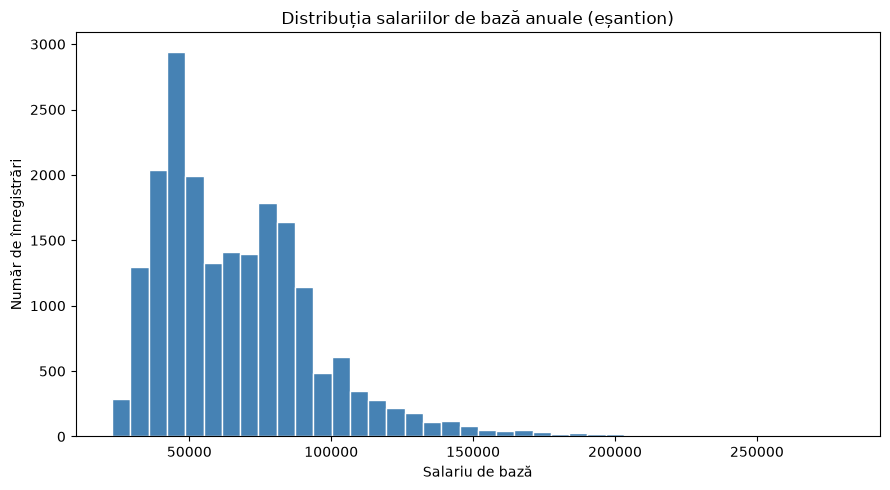

In [18]:
import matplotlib.pyplot as plt

salary_sample = (
    clean_payroll
    .filter(F.lower(F.trim(F.col("pay_basis"))) == "per annum")
    .select("base_salary")
    .sample(withReplacement=False, fraction=0.02, seed=42)
    .limit(20_000)
    .toPandas()
)

if salary_sample.empty:
    raise ValueError("Nu există rânduri cu pay_basis='per Annum' pentru histogramă.")

plt.figure(figsize=(9, 5))
plt.hist(salary_sample["base_salary"], bins=40, color="steelblue", edgecolor="white")
plt.title("Distribuția salariilor de bază anuale (eșantion)")
plt.xlabel("Salariu de bază")
plt.ylabel("Număr de înregistrări")
plt.tight_layout()
plt.show()

Histograma arată distribuția salariilor anuale dintr-un eșantion. Verifică asimetria și valorile extreme; nu amestecăm ratele orare în această comparație.

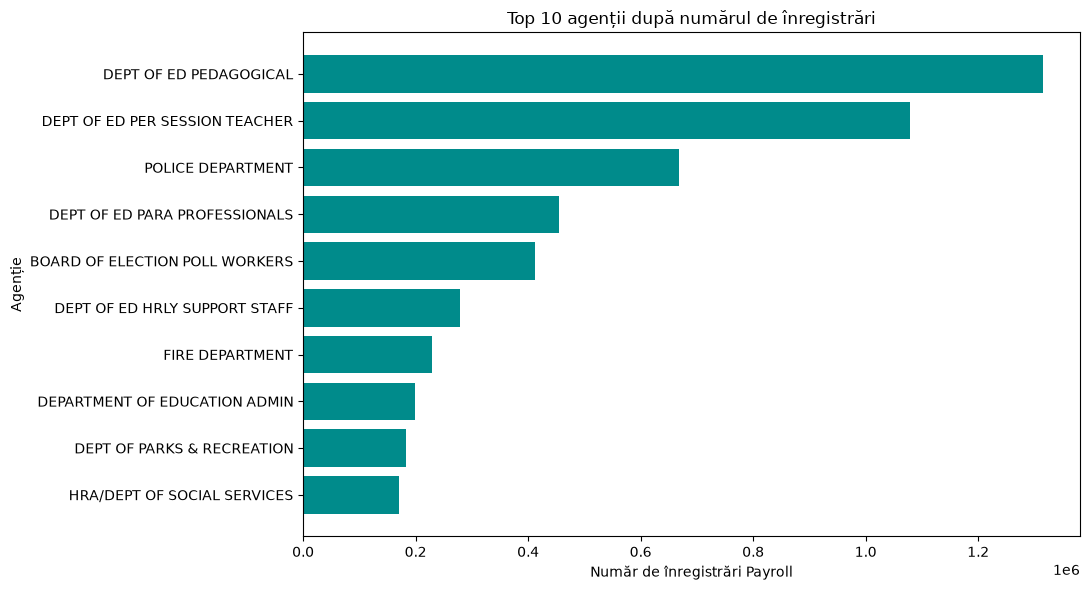

In [19]:
top_agencies_pd = agency_metrics.limit(10).toPandas()

plt.figure(figsize=(11, 6))
plt.barh(
    top_agencies_pd["agency_name"][::-1],
    top_agencies_pd["payroll_records"][::-1],
    color="darkcyan",
)
plt.title("Top 10 agenții după numărul de înregistrări")
plt.xlabel("Număr de înregistrări Payroll")
plt.ylabel("Agenție")
plt.tight_layout()
plt.show()

Graficul compară volumul înregistrărilor pe agenție, nu numărul exact de angajați unici. Diferența poate reflecta mai mulți ani de date și tipuri diferite de plăți.

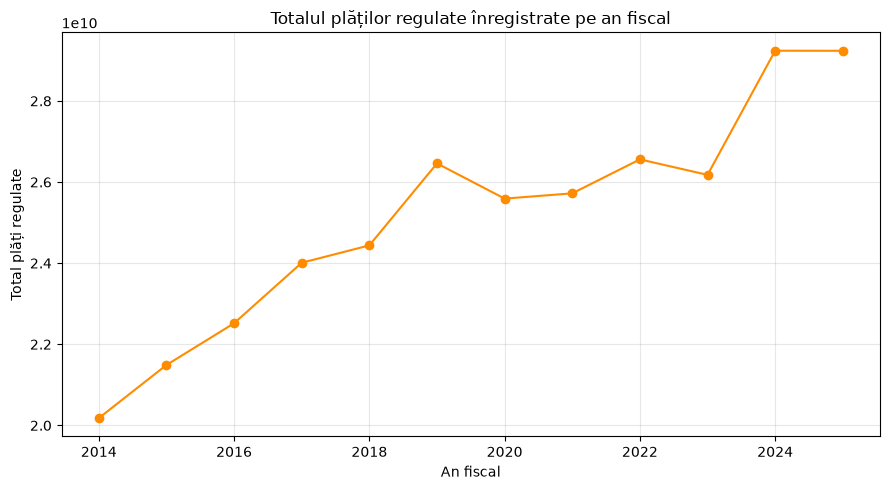

In [20]:
year_metrics_pd = year_metrics.orderBy("fiscal_year").toPandas()

plt.figure(figsize=(9, 5))
plt.plot(
    year_metrics_pd["fiscal_year"],
    year_metrics_pd["regular_gross_total"],
    marker="o",
    color="darkorange",
)
plt.title("Totalul plăților regulate înregistrate pe an fiscal")
plt.xlabel("An fiscal")
plt.ylabel("Total plăți regulate")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretarea rezultatelor și concluzii pentru stakeholder

- **Trend principal:** folosește graficul pe ani și tabelul SQL pentru a identifica anii cu creșteri/scăderi ale plăților regulate și ale orelor suplimentare.
- **Pattern de investigat:** compară topul agențiilor cu distribuția salariilor pe pay_basis. Numărul mare de rânduri nu înseamnă automat salariu mediu sau cost total mai mare.
- **Concluzie pentru prezentare:** arată agențiile și perioadele care contribuie cel mai mult la totalurile observate, apoi explică limitările (rânduri, nu persoane unice; potrivirea exactă a numelor între surse).

Aceste concluzii sunt întrebări de analiză; validează-le cu valorile și graficele generate după rularea notebookului.

## 6. Streaming simulat: Kafka → Spark Structured Streaming → MongoDB

Fluxul obligatoriu este simulat dintr-un eșantion al setului static. Producerul adaugă un timestamp artificial de ingestie, Kafka păstrează evenimentele, Spark le citește în micro-batch-uri și calculează media salariului și plata overtime în ferestre de 10 secunde. Rezultatele agregate sunt salvate cu upsert în MongoDB.

### Pornirea serviciilor

Din terminal, în directorul proiectului, rulează:

    docker compose -f docker-compose.streaming.yml up -d

Compose publică Kafka pe portul 9094 și MongoDB pe 27017. Din containerul Jupyter de pe Docker Desktop, serviciile sunt accesate prin host.docker.internal. În notebook instalează pachetele Python necesare o singură dată:

    %pip install kafka-python pymongo

Conectorul Spark-Kafka se descarcă la inițializarea SparkSession-ului, de aceea kernelul trebuie repornit după configurarea mediului. Folosește volumele de date doar pentru test local fără date sensibile.

### Producer și consumer cu agregare pe ferestre

Producerul publică un număr configurabil de înregistrări în loturi temporizate, fiecare cu timestamp artificial. Spark calculează ferestre de 10 secunde și separă rezultatele și mediile după `pay_basis`, ca să nu amestece salarii anuale și orare. Watermark-ul de un minut gestionează evenimentele întârziate; rezultatele sunt upsert-uite în MongoDB.

Parametrii de la începutul celulei limitează fluxul la maximum 5.000 de mesaje pentru o rulare. Crește loturile numai dacă resursele containerului permit.

In [24]:
import itertools
import json
import time
from datetime import datetime, timezone

from kafka import KafkaProducer
from pymongo import MongoClient
from pyspark.sql import types as T

KAFKA_BOOTSTRAP = os.getenv(
    "KAFKA_BOOTSTRAP_SERVERS", "host.docker.internal:9094"
)
MONGO_URI = os.getenv("MONGO_URI", "mongodb://host.docker.internal:27017")
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%d%H%M%S")
TOPIC = f"lab1-payroll-{RUN_ID}"

NUM_BATCHES = 6
EVENTS_PER_BATCH = 100
MAX_TOTAL_EVENTS = 5_000
PAUSE_SECONDS = 5
SAMPLE_FRACTION = 0.02
TOTAL_EVENTS = NUM_BATCHES * EVENTS_PER_BATCH

if NUM_BATCHES <= 0 or EVENTS_PER_BATCH <= 0:
    raise ValueError("Numărul loturilor și mărimea lor trebuie să fie pozitive.")
if TOTAL_EVENTS > MAX_TOTAL_EVENTS:
    raise ValueError(
        f"Rularea ar publica {TOTAL_EVENTS} evenimente; limita este "
        f"{MAX_TOTAL_EVENTS}. Redu parametrii sau ridică explicit limita."
    )

mongo_client = MongoClient(MONGO_URI, serverSelectionTimeoutMS=5000)
mongo_client.admin.command("ping")
mongo_collection = mongo_client["lab1"]["payroll_windows"]

producer = KafkaProducer(
    bootstrap_servers=KAFKA_BOOTSTRAP,
    value_serializer=lambda value: json.dumps(value, default=str).encode("utf-8"),
    acks="all",
    retries=3,
)

event_schema = T.StructType([
    T.StructField("event_time", T.TimestampType(), True),
    T.StructField("agency_name", T.StringType(), True),
    T.StructField("fiscal_year", T.IntegerType(), True),
    T.StructField("pay_basis", T.StringType(), True),
    T.StructField("base_salary", T.DoubleType(), True),
    T.StructField("total_ot_paid", T.DoubleType(), True),
])

sampled_events = (
    clean_payroll
    .select(
        "agency_name", "fiscal_year", "pay_basis",
        "base_salary", "total_ot_paid",
    )
    .sample(withReplacement=False, fraction=SAMPLE_FRACTION, seed=7)
    .limit(TOTAL_EVENTS)
    .toLocalIterator()
)

streaming_events = (
    spark.readStream
    .format("kafka")
    .option("kafka.bootstrap.servers", KAFKA_BOOTSTRAP)
    .option("subscribe", TOPIC)
    .option("startingOffsets", "earliest")
    .load()
    .select(
        F.from_json(F.col("value").cast("string"), event_schema).alias("event")
    )
    .select("event.*")
    .filter(
        F.col("event_time").isNotNull()
        & F.col("agency_name").isNotNull()
        & F.col("pay_basis").isNotNull()
    )
    .withWatermark("event_time", "1 minute")
)

windowed_metrics = (
    streaming_events
    .groupBy(
        F.window(F.col("event_time"), "10 seconds"),
        F.col("agency_name"),
        F.col("pay_basis"),
    )
    .agg(
        F.count("*").alias("event_count"),
        F.round(F.avg("base_salary"), 2).alias("avg_base_salary"),
        F.round(F.sum("total_ot_paid"), 2).alias("overtime_pay_total"),
    )
)


def write_window_batch(batch_df, batch_id):
    for row in batch_df.toLocalIterator():
        result = row.asDict(recursive=True)
        window_value = result.pop("window")
        window_start = window_value["start"]
        window_end = window_value["end"]
        result.update({
            "_id": (
                f"{RUN_ID}|{result['agency_name']}|{result['pay_basis']}|"
                f"{window_start.isoformat()}"
            ),
            "run_id": RUN_ID,
            "window_start": window_start,
            "window_end": window_end,
            "batch_id": batch_id,
        })
        mongo_collection.replace_one(
            {"_id": result["_id"]}, result, upsert=True
        )


stream_query = (
    windowed_metrics.writeStream
    .outputMode("update")
    .foreachBatch(write_window_batch)
    .option(
        "checkpointLocation",
        str(PROJECT_ROOT / "checkpoints" / f"kafka-{RUN_ID}"),
    )
    .trigger(processingTime="2 seconds")
    .start()
)

try:
    event_iterator = iter(sampled_events)
    published = 0
    for batch_number in range(NUM_BATCHES):
        batch = list(itertools.islice(event_iterator, EVENTS_PER_BATCH))
        if not batch:
            break
        event_time = datetime.now(timezone.utc).isoformat()
        for row in batch:
            message = row.asDict()
            message["event_time"] = event_time
            producer.send(TOPIC, value=message)
            published += 1
        producer.flush()
        print(f"Lot {batch_number + 1}: {len(batch)} evenimente publicate")
        if batch_number < NUM_BATCHES - 1:
            time.sleep(PAUSE_SECONDS)

    stream_query.processAllAvailable()
    stored = mongo_collection.count_documents({"run_id": RUN_ID})
    print(f"Evenimente Kafka publicate: {published}")
    print(f"Agregări de fereastră salvate în MongoDB: {stored}")
    if stored == 0:
        raise RuntimeError(
            "Nu s-au găsit agregări în MongoDB. Verifică brokerul Kafka, "
            "conectorul Spark-Kafka și logurile query-ului."
        )
finally:
    producer.close()
    stream_query.stop()
    mongo_client.close()

Lot 1: 100 evenimente publicate
Lot 2: 100 evenimente publicate
Lot 3: 100 evenimente publicate
Lot 4: 100 evenimente publicate
Lot 5: 100 evenimente publicate
Lot 6: 100 evenimente publicate
Evenimente Kafka publicate: 600
Agregări de fereastră salvate în MongoDB: 9


### Grafic pentru ferestrele scrise în MongoDB

Citim numai agregările run-ului curent din MongoDB și reprezentăm numărul de evenimente pe fereastră. Acesta este graficul rezultatului streaming; nu transferăm mesajele brute în Pandas.

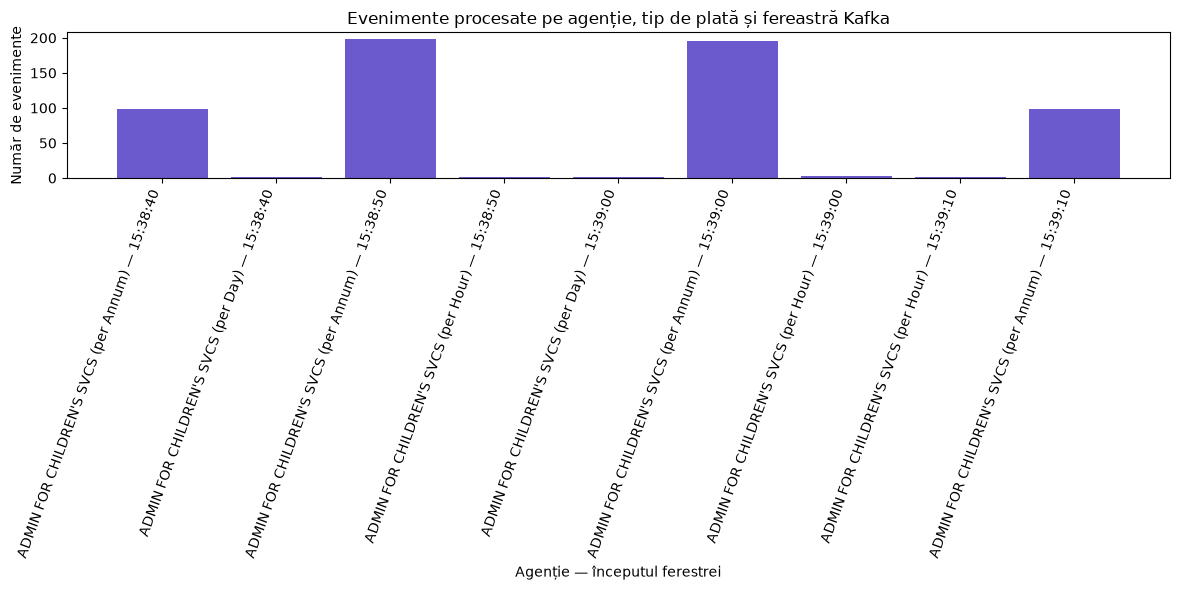

,agency_name,pay_basis,event_count,avg_base_salary,window_start,window_label,series
0,ADMIN FOR CHILDREN'S SVCS,per Annum,99,87360.55,2026-10-22 15:38:40,15:38:40,ADMIN FOR CHILDREN'S SVCS (per Annum) — 15:38:40
1,ADMIN FOR CHILDREN'S SVCS,per Day,1,331.92,2026-10-22 15:38:40,15:38:40,ADMIN FOR CHILDREN'S SVCS (per Day) — 15:38:40
2,ADMIN FOR CHILDREN'S SVCS,per Annum,198,77060.84,2026-10-22 15:38:50,15:38:50,ADMIN FOR CHILDREN'S SVCS (per Annum) — 15:38:50
3,ADMIN FOR CHILDREN'S SVCS,per Hour,2,29.30,2026-10-22 15:38:50,15:38:50,ADMIN FOR CHILDREN'S SVCS (per Hour) — 15:38:50
4,ADMIN FOR CHILDREN'S SVCS,per Day,2,344.01,2026-10-22 15:39:00,15:39:00,ADMIN FOR CHILDREN'S SVCS (per Day) — 15:39:00
5,ADMIN FOR CHILDREN'S SVCS,per Annum,195,70735.75,2026-10-22 15:39:00,15:39:00,ADMIN FOR CHILDREN'S SVCS (per Annum) — 15:39:00
6,ADMIN FOR CHILDREN'S SVCS,per Hour,3,18.97,2026-10-22 15:39:00,15:39:00,ADMIN FOR CHILDREN'S SVCS (per Hour) — 15:39:00
7,ADMIN FOR CHILDREN'S SVCS,per Hour,1,29.04,2026-10-22 15:39:10,15:39:10,ADMIN FOR CHILDREN'S SVCS (per Hour) — 15:39:10
8,ADMIN FOR CHILDREN'S SVCS,per Annum,99,71067.24,2026-10-22 15:39:10,15:39:10,ADMIN FOR CHILDREN'S SVCS (per Annum) — 15:39:10


In [22]:
from pymongo import MongoClient
import pandas as pd

mongo_client = MongoClient(MONGO_URI, serverSelectionTimeoutMS=5000)
mongo_collection = mongo_client["lab1"]["payroll_windows"]
window_documents = list(
    mongo_collection.find(
        {"run_id": RUN_ID},
        {
            "_id": 0,
            "agency_name": 1,
            "window_start": 1,
            "event_count": 1,
            "avg_base_salary": 1,
            "pay_basis": 1,
        },
    ).sort("window_start", 1)
)
mongo_client.close()

if not window_documents:
    raise ValueError("MongoDB nu conține agregări pentru această rulare.")

stream_results = pd.DataFrame(window_documents)
stream_results["window_label"] = (
    stream_results["window_start"].astype(str).str.slice(11, 19)
)
stream_results["series"] = (
    stream_results["agency_name"] + " (" + stream_results["pay_basis"] + ") — "
    + stream_results["window_label"]
)

plt.figure(figsize=(12, 6))
plt.bar(
    stream_results["series"],
    stream_results["event_count"],
    color="slateblue",
)
plt.title("Evenimente procesate pe agenție, tip de plată și fereastră Kafka")
plt.xlabel("Agenție — începutul ferestrei")
plt.ylabel("Număr de evenimente")
plt.xticks(rotation=70, ha="right")
plt.tight_layout()
plt.show()

display(stream_results.head(10))

### Arhitectură, Kafka și limitările simulării

- **De ce pare neobișnuit Data Lake → Kafka → NoSQL?** Kafka este în mod normal stratul de transport al evenimentelor, nu o etapă necesară după stocarea istorică. Pipeline-ul obișnuit este sursă live → Kafka → Spark/Flink → data lake pentru istoric și/sau MongoDB/warehouse pentru servire. Aici reluăm date statice prin Kafka doar ca să exersăm fluxul.
- **De ce Kafka, nu citire directă în Spark?** Kafka decuplează producerul de consumatori, păstrează evenimentele pentru replay și distribuie fluxul către mai multe aplicații. Fără Kafka, producerul și Spark sunt strâns legate, replay-ul și gestionarea producerilor multipli sunt mai dificile, iar întreruperile pot duce la pierderi dacă nu există buffering persistent.
- **Limitările simulării:** timestamp-urile sunt artificiale; ordinea, ritmul și distribuția istorică nu reproduc trafic real. Simularea nu testează fidel întârzieri, duplicate, căderi de rețea, backpressure, partiționare, volume susținute sau evenimente out-of-order. Pentru date live, aceste cazuri trebuie testate separat.
- **Insight streaming:** agregarea pe ferestre arată câte înregistrări și ce salariu mediu au ajuns pentru fiecare agenție în fiecare interval. Interpretarea depinde de eșantionul și ritmul artificial al producerului.

## 8. Dashboard interactiv pentru stakeholderi

Dashboardul Plotly rulează în notebook și permite filtrarea după an, tip de plată și număr de agenții afișate. Include costurile salariale înregistrate, evoluția anuală și mediile salariului de bază pe tip de plată. Mediile din pay_basis-uri diferite au unități diferite și trebuie comparate numai în interiorul aceleiași categorii.

Celula exportă și tabele agregate CSV pentru import în Tableau sau Power BI (folosește fișierul `part-*.csv` din fiecare director), precum și o versiune HTML interactivă a graficului curent.

In [25]:
import ipywidgets as widgets
import plotly.graph_objects as go
from IPython.display import display
from plotly.subplots import make_subplots

dashboard_agencies_pd = agency_year_metrics.toPandas()
dashboard_years_pd = year_basis_metrics.toPandas()
dashboard_year_options = sorted(
    int(year) for year in dashboard_years_pd["fiscal_year"].unique()
)
dashboard_basis_options = sorted(
    str(basis) for basis in dashboard_years_pd["pay_basis"].dropna().unique()
)
dashboard_all_label = "Toate tipurile"


def build_dashboard_figure(selected_basis, selected_year, top_n):
    year_data = dashboard_agencies_pd[
        dashboard_agencies_pd["fiscal_year"] == selected_year
    ]
    yearly_data = dashboard_years_pd.copy()

    if selected_basis != dashboard_all_label:
        year_data = year_data[year_data["pay_basis"] == selected_basis]
        yearly_data = yearly_data[yearly_data["pay_basis"] == selected_basis]
        agency_data = year_data[
            [
                "agency_name", "payroll_records",
                "regular_gross_total", "overtime_pay_total",
            ]
        ].copy()
        trend_data = yearly_data[
            ["fiscal_year", "regular_gross_total"]
        ].copy()
        trend_data = trend_data.rename(
            columns={"regular_gross_total": "paid_total"}
        )
    else:
        agency_data = (
            year_data.groupby("agency_name", as_index=False)
            .agg(
                payroll_records=("payroll_records", "sum"),
                regular_gross_total=("regular_gross_total", "sum"),
                overtime_pay_total=("overtime_pay_total", "sum"),
            )
        )
        trend_data = (
            yearly_data.groupby("fiscal_year", as_index=False)
            .agg(paid_total=("regular_gross_total", "sum"))
        )

    top_agencies = agency_data.nlargest(
        top_n, "regular_gross_total"
    ).sort_values("regular_gross_total")
    salary_data = dashboard_years_pd[
        dashboard_years_pd["fiscal_year"] == selected_year
    ].sort_values("pay_basis")

    figure = make_subplots(
        rows=1,
        cols=3,
        subplot_titles=(
            "Top agenții — plăți regulate",
            "Evoluția plăților regulate",
            "Media salariului de bază pe pay_basis",
        ),
        horizontal_spacing=0.12,
    )
    figure.add_trace(
        go.Bar(
            x=top_agencies["regular_gross_total"],
            y=top_agencies["agency_name"],
            orientation="h",
            customdata=top_agencies[["payroll_records"]],
            hovertemplate=(
                "%{y}<br>Plăți: $%{x:,.2f}"
                "<br>Înregistrări: %{customdata[0]:,}<extra></extra>"
            ),
            marker_color="#1976d2",
        ),
        row=1,
        col=1,
    )
    figure.add_trace(
        go.Scatter(
            x=trend_data["fiscal_year"],
            y=trend_data["paid_total"],
            mode="lines+markers",
            hovertemplate="An %{x}<br>Plăți: $%{y:,.2f}<extra></extra>",
            line_color="#ef6c00",
        ),
        row=1,
        col=2,
    )
    figure.add_trace(
        go.Bar(
            x=salary_data["pay_basis"],
            y=salary_data["avg_base_salary"],
            hovertemplate=(
                "%{x}<br>Media ratei de bază: $%{y:,.2f}<extra></extra>"
            ),
            marker_color="#388e3c",
        ),
        row=1,
        col=3,
    )
    figure.update_xaxes(title_text="Plăți înregistrate ($)", row=1, col=1)
    figure.update_xaxes(title_text="An fiscal", row=1, col=2)
    figure.update_xaxes(title_text="Tip de plată", row=1, col=3)
    figure.update_yaxes(title_text="Agenție", row=1, col=1)
    figure.update_yaxes(title_text="Plăți înregistrate ($)", row=1, col=2)
    figure.update_yaxes(title_text="Rată de bază ($)", row=1, col=3)
    figure.update_layout(
        title=(
            f"NYC Payroll — {selected_year}, "
            f"{selected_basis}; totalurile sunt sume plătite"
        ),
        height=620,
        showlegend=False,
        margin={"l": 20, "r": 20, "t": 90, "b": 50},
    )
    return figure


basis_widget = widgets.Dropdown(
    options=[dashboard_all_label, *dashboard_basis_options],
    value=dashboard_all_label,
    description="Tip plată:",
    layout=widgets.Layout(width="300px"),
)
year_widget = widgets.Dropdown(
    options=dashboard_year_options,
    value=max(dashboard_year_options),
    description="An fiscal:",
    layout=widgets.Layout(width="220px"),
)
top_n_widget = widgets.IntSlider(
    value=10,
    min=5,
    max=20,
    step=5,
    description="Top agenții:",
    continuous_update=False,
    layout=widgets.Layout(width="300px"),
)


def show_dashboard(selected_basis, selected_year, top_n):
    display(
        build_dashboard_figure(
            selected_basis, selected_year, top_n
        )
    )


dashboard_output = widgets.interactive_output(
    show_dashboard,
    {
        "selected_basis": basis_widget,
        "selected_year": year_widget,
        "top_n": top_n_widget,
    },
)
display(
    widgets.VBox([
        widgets.HBox([basis_widget, year_widget, top_n_widget]),
        dashboard_output,
    ])
)

dashboard_dir = LAKE_DIR / "dashboard"
dashboard_dir.mkdir(parents=True, exist_ok=True)
dashboard_html = dashboard_dir / "nyc_payroll_dashboard.html"
default_dashboard = build_dashboard_figure(
    dashboard_all_label, max(dashboard_year_options), 10
)
default_dashboard.write_html(
    str(dashboard_html),
    include_plotlyjs=True,
    full_html=True,
)
print(f"Dashboard HTML interactiv salvat în: {dashboard_html}")

dashboard_exports = {
    "pay_basis_metrics": pay_basis_metrics,
    "year_basis_metrics": year_basis_metrics,
    "yearly_payments": year_metrics,
    "agency_payments": agency_metrics,
    "annual_agency_salary": annual_agency_metrics,
    "payroll_civil_comparison": agency_comparison,
}
for table_name, table_df in dashboard_exports.items():
    output_path = dashboard_dir / table_name
    (
        table_df.coalesce(1)
        .write.mode("overwrite")
        .option("header", "true")
        .csv(str(output_path))
    )
    print(f"CSV pentru Tableau/Power BI: {output_path}")

Dashboard HTML interactiv salvat în: /home/jovyan/work/Lab1/data_lake/dashboard/nyc_payroll_dashboard.html
CSV pentru Tableau/Power BI: /home/jovyan/work/Lab1/data_lake/dashboard/pay_basis_metrics
CSV pentru Tableau/Power BI: /home/jovyan/work/Lab1/data_lake/dashboard/year_basis_metrics
CSV pentru Tableau/Power BI: /home/jovyan/work/Lab1/data_lake/dashboard/yearly_payments
CSV pentru Tableau/Power BI: /home/jovyan/work/Lab1/data_lake/dashboard/agency_payments
CSV pentru Tableau/Power BI: /home/jovyan/work/Lab1/data_lake/dashboard/annual_agency_salary
CSV pentru Tableau/Power BI: /home/jovyan/work/Lab1/data_lake/dashboard/payroll_civil_comparison


## 9. Concluzii și schiță pentru prezentarea de 5–10 minute

1. **Dataset și limitare:** explică sursele NYC Payroll/Civil List și menționează că fișierele locale au aproximativ 395 MB, sub pragul cerut de 2 GB.
2. **Pipeline:** Parquet local → PySpark → curățare → Spark SQL → grafice/dashboard; pentru simulare: eșantion istoric → Kafka → Spark Structured Streaming → MongoDB.
3. **Curățare:** prezintă conversia șirurilor monetare, regulile de filtrare și numărul de rânduri păstrate.
4. **Metrici:** separă mediile după pay_basis; interpretează totalurile drept sume nominale ale plăților înregistrate, nu număr de angajați unici.
5. **Join:** raportează procentul de agenții și de înregistrări Payroll potrivite; explică aliasurile exacte și potrivirile lipsă.
6. **Streaming și vizualizare:** demonstrează ferestrele, watermark-ul, rezultatul MongoDB și dashboardul exportat; explică limitele datelor statice.

Valorile din concluzii se calculează la rulare. Dashboardul HTML și CSV-urile agregate se găsesc în `data_lake/dashboard/`.